In [1]:
from pathlib import Path
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
tf.random.set_seed(SEED)
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS = 66, 200, 3
INPUT_SHAPE = (IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)


print("TensorFlow:", tf.__version__)
print("Project:", PROJECT_ROOT)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("CNN input shape:", INPUT_SHAPE)

TensorFlow: 2.21.0
Project: C:\Users\user\Neuro Drive
GPU devices: []
CNN input shape: (66, 200, 3)


In [2]:
def build_neurodrive_model(input_shape=INPUT_SHAPE):
    return keras.Sequential([
        layers.Input(shape=input_shape, name="camera_image"),
        layers.Rescaling(1.0 / 255.0, offset=-0.5, name="pixel_normalisation"),

        layers.Conv2D(24, (5, 5), strides=(2, 2), activation="relu", name="conv1"),
        layers.Conv2D(36, (5, 5), strides=(2, 2), activation="relu", name="conv2"),
        layers.Conv2D(48, (5, 5), strides=(2, 2), activation="relu", name="conv3"),
        layers.Conv2D(64, (3, 3), strides=(1, 1), activation="relu", name="conv4"),
        layers.Conv2D(64, (3, 3), strides=(1, 1), activation="relu", name="conv5"),

        layers.Flatten(name="flatten"),
        layers.Dense(100, activation="relu", name="dense1"),
        layers.Dense(50, activation="relu", name="dense2"),
        layers.Dense(10, activation="relu", name="dense3"),
        layers.Dense(1, activation="linear", name="steering_output"),
    ], name="NeuroDrive_NVIDIA_CNN")

model = build_neurodrive_model()
model.summary()

Model: "NeuroDrive_NVIDIA_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ pixel_normalisation (Rescaling)      │ (None, 66, 200, 3)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1 (Conv2D)                       │ (None, 31, 98, 24)          │           1,824 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2 (Conv2D)                       │ (None, 14, 47, 36)          │          21,636 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3 (Conv2D)                       │ (None, 5, 22, 48)           │          43,248 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv4 (Conv2D)                       │ (None, 3, 20, 64)           │          27,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv5 (Conv2D)                       │ (None, 1, 18, 64)           │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1152)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense1 (Dense)                       │ (None, 100)                 │         115,300 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense2 (Dense)                       │ (None, 50)                  │           5,050 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense3 (Dense)                       │ (None, 10)                  │             510 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ steering_output (Dense)              │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 252,219 (985.23 KB)

 Trainable params: 252,219 (985.23 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
for layer in model.layers:
    print(f"{layer.name:25s} -> {layer.output.shape}")

pixel_normalisation       -> (None, 66, 200, 3)
conv1                     -> (None, 31, 98, 24)
conv2                     -> (None, 14, 47, 36)
conv3                     -> (None, 5, 22, 48)
conv4                     -> (None, 3, 20, 64)
conv5                     -> (None, 1, 18, 64)
flatten                   -> (None, 1152)
dense1                    -> (None, 100)
dense2                    -> (None, 50)
dense3                    -> (None, 10)
steering_output           -> (None, 1)


In [4]:
dummy_images = tf.zeros((2, IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS), dtype=tf.uint8)
predictions = model(dummy_images, training=False)
print("Input:", dummy_images.shape)
print("Output:", predictions.shape)
print("Predictions:", predictions.numpy().ravel())

Input: (2, 66, 200, 3)
Output: (2, 1)
Predictions: [0.00651944 0.00651944]


In [5]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="mse",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")]
)

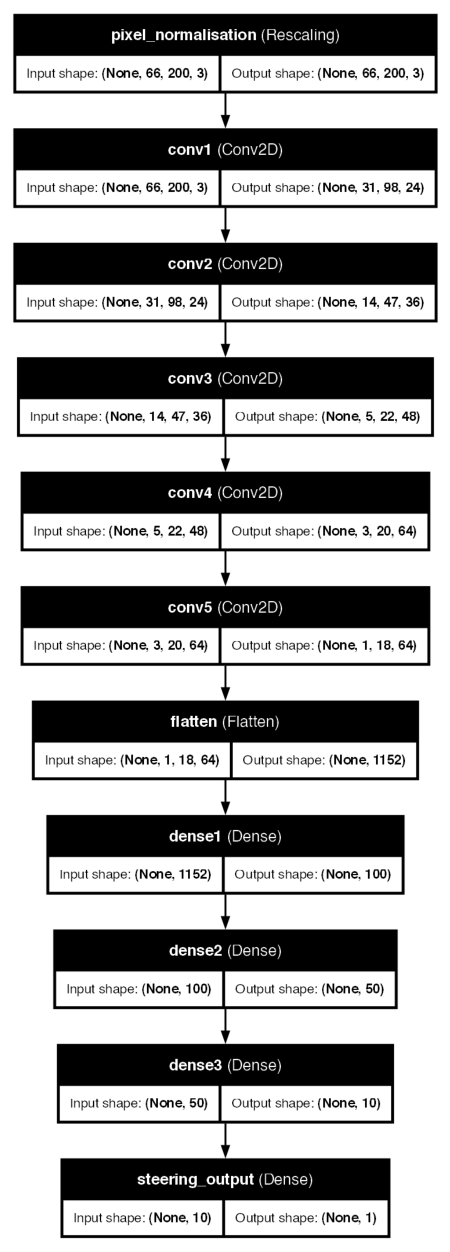

In [6]:
try:
    keras.utils.plot_model(
        model, to_file=str(MODEL_DIR / "neurodrive_architecture.png"),
        show_shapes=True, show_layer_names=True, dpi=120
    )
    image = plt.imread(MODEL_DIR / "neurodrive_architecture.png")
    plt.figure(figsize=(12, 16))
    plt.imshow(image)
    plt.axis("off")
    plt.show()
except Exception as error:
    print("Architecture plot unavailable:", error)
    print("Optional: pip install pydot; install Graphviz separately and add it to PATH.")

In [7]:
architecture_path = MODEL_DIR / "neurodrive_untrained.keras"
model.save(architecture_path)
print("Saved:", architecture_path)

Saved: C:\Users\user\Neuro Drive\models\neurodrive_untrained.keras
